### Seoul Bike — Random Forest
Predict hourly bike rentals using weather, hour, and calendar features. Model selection uses a chronological Train (70%) / Validation (15%) / Test (15%) split. Lower MAE and RMSE are better; higher R² is better.

The same split and Random Forest settings are used when comparing feature sets. The Test set is reserved for the final evaluation in this notebook.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Load and prepare data
df = pd.read_csv("../data/SeoulBikeData.csv", encoding="latin1")
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df = (
    df[df["Functioning Day"] == "Yes"]
    .sort_values(["Date", "Hour"])
    .reset_index(drop=True)
)

df["DayOfWeek"] = df["Date"].dt.day_of_week 
df["IsHoliday"] = (df["Holiday"] == "Holiday").astype(int)

# Original selected features
base_features = [
    "Hour",
    "Temperature(°C)",
    "Rainfall(mm)",
    "Humidity(%)",
    "IsHoliday",
    "DayOfWeek",
]

# Weather features suggested on group meeting
weather_features = [
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)",
    "Rainfall(mm)",
    "Snowfall (cm)",
]

feature_sets = {
    "Selected 6 features": base_features,
    "Weather + Hour (9)": ["Hour"] + weather_features,
    "Weather + Hour + calendar (11)": ["Hour"] + weather_features + ["DayOfWeek", "IsHoliday"],
}

x = df[base_features]
y = df["Rented Bike Count"]

# Keep later observations out of training
train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.85)

x_train = x.iloc[:train_end]
x_val = x.iloc[train_end:val_end]
y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print(f"Train: {train_end}, Validation: {val_end - train_end}, Test: {len(df) - val_end}")

Train: 5925, Validation: 1270, Test: 1270


#### 1. Initial Random Forest
Start with 100 trees and unrestricted depth. Compare training and validation errors to check overfitting.

In [8]:
def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    }

forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
forest.fit(x_train, y_train)

initial_results = pd.DataFrame([
    {"Split": "Train", **regression_metrics(y_train, forest.predict(x_train))},
    {"Split": "Validation", **regression_metrics(y_val, forest.predict(x_val))},
])
display(initial_results.round(3))

,Split,MAE,RMSE,R²
0,Train,39.414,68.353,0.989
1,Validation,183.278,288.066,0.809


#### 2. Choose tree depth
Compare depth values on the Validation period. Increasing depth may fit training data better without improving predictions on new data.

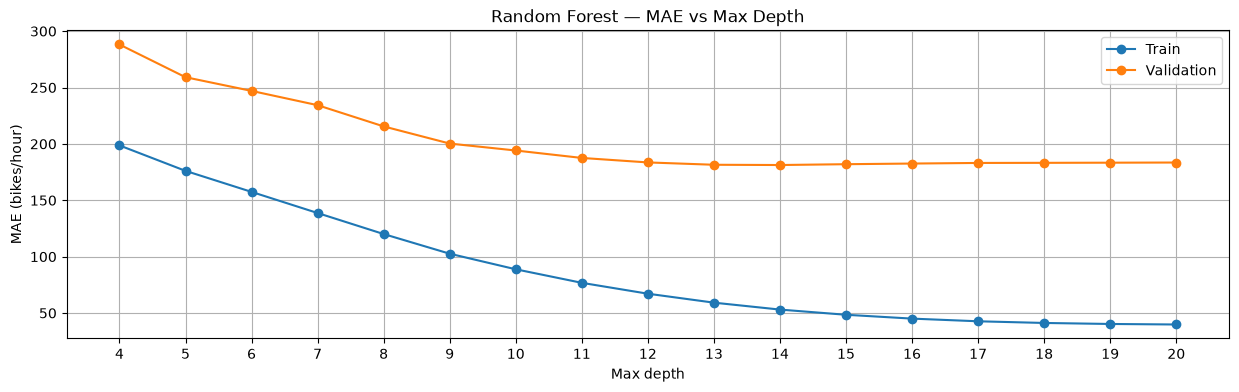

Best depth: 14
Best Validation MAE: 181.26


In [15]:
depth_results = []

for depth in range(4, 21):
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(x_train, y_train)
    depth_results.append({
        "Depth": depth,
        "Train MAE": mean_absolute_error(y_train, model.predict(x_train)),
        "Validation MAE": mean_absolute_error(y_val, model.predict(x_val)),
    })

depth_results = pd.DataFrame(depth_results)
best_depth = int(depth_results.loc[depth_results["Validation MAE"].idxmin(), "Depth"])

plt.figure(figsize=(15, 4))
plt.plot(depth_results["Depth"], depth_results["Train MAE"], marker="o", label="Train")
plt.plot(depth_results["Depth"], depth_results["Validation MAE"], marker="o", label="Validation")
plt.title("Random Forest — MAE vs Max Depth")
plt.xlabel("Max depth")
plt.ylabel("MAE (bikes/hour)")
plt.xticks(depth_results["Depth"])
plt.legend()
plt.grid(True)
plt.show()

print(f"Best depth: {best_depth}")
print(f"Best Validation MAE: {depth_results['Validation MAE'].min():.2f}")

#### 3. Choose number of trees
More trees usually increase computation time. If the validation curve levels off, 50 trees can be a practical choice even when a larger forest has a slightly lower MAE.

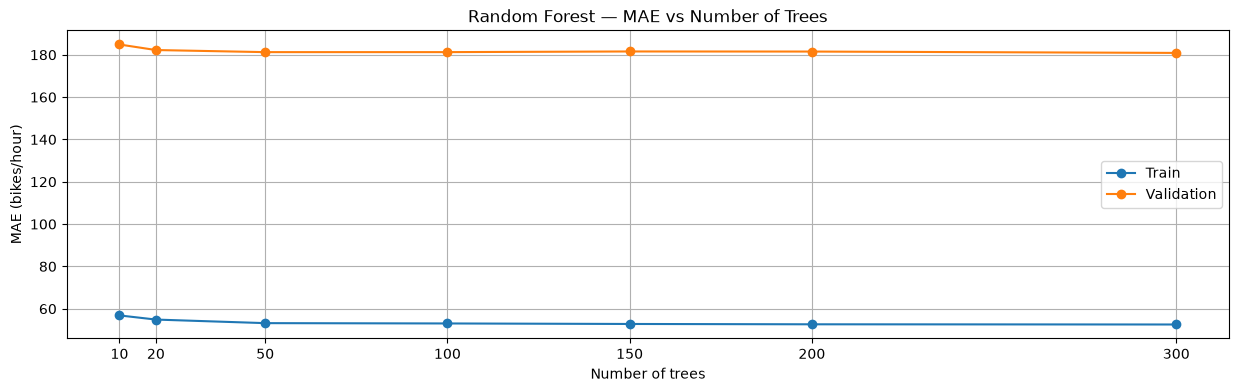

Selected number of trees: 50


,Trees,Train MAE,Validation MAE
0,10,56.85,184.86
1,20,54.89,182.24
2,50,53.20,181.25
3,100,53.05,181.26
4,150,52.80,181.57
5,200,52.65,181.53
6,300,52.56,180.88


In [16]:
count_results = []

for count in [10, 20, 50, 100, 150, 200, 300]:
    model = RandomForestRegressor(
        n_estimators=count,
        max_depth=best_depth,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(x_train, y_train)
    count_results.append({
        "Trees": count,
        "Train MAE": mean_absolute_error(y_train, model.predict(x_train)),
        "Validation MAE": mean_absolute_error(y_val, model.predict(x_val)),
    })

count_results = pd.DataFrame(count_results)

plt.figure(figsize=(15, 4))
plt.plot(count_results["Trees"], count_results["Train MAE"], marker="o", label="Train")
plt.plot(count_results["Trees"], count_results["Validation MAE"], marker="o", label="Validation")
plt.title("Random Forest — MAE vs Number of Trees")
plt.xlabel("Number of trees")
plt.ylabel("MAE (bikes/hour)")
plt.xticks(count_results["Trees"])
plt.legend()
plt.grid(True)
plt.show()

chosen_count = 50
print(f"Selected number of trees: {chosen_count}")
display(count_results.round(2))

#### 4. Compare feature sets
Compare the **original six features** with the **weather features** suggested on group meeting, first with hour alone and then with calendar information.  
Only the features change; split and forest settings stay the same.

In [17]:
feature_results = []

for name, columns in feature_sets.items():
    x_current = df[columns]
    model = RandomForestRegressor(
        n_estimators=chosen_count,
        max_depth=best_depth,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(x_current.iloc[:train_end], y_train)
    validation_pred = model.predict(x_current.iloc[train_end:val_end])
    feature_results.append({
        "Feature set": name,
        "Features": len(columns),
        **regression_metrics(y_val, validation_pred),
    })

feature_comparison = pd.DataFrame(feature_results).sort_values("MAE").reset_index(drop=True)
display(feature_comparison.round(3))

,Feature set,Features,MAE,RMSE,R²
0,Weather + Hour + calendar (11),11,180.630,271.260,0.831
1,Selected 6 features,6,181.252,286.435,0.811
2,Weather + Hour (9),9,220.758,319.028,0.766


**Observations:**
- **MAE:** Almost identical for 6 and 11 features. The five additional features barely improve the average prediction error.
- **RMSE:** Noticeably lower with 11 features (271.26 vs 286.44), suggesting fewer or smaller large prediction errors.
- **R²:** Improves slightly from 0.811 to 0.831, meaning the 11-feature model explains more of the variation in bike rentals.

**Conclusion:** The 11-feature model performs slightly better overall, but the 6-feature model achieves nearly the same MAE with fewer inputs.

#### 5. Final evaluation on Test
Select the feature set with the lowest Validation MAE. Refit on Train + Validation and evaluate on the later Test period. Do not use the Test result to select new settings.

In [21]:
best_feature_set = feature_comparison.loc[0, "Feature set"]
final_features = feature_sets[best_feature_set]
x_final = df[final_features]

final_forest = RandomForestRegressor(
    n_estimators=chosen_count,
    max_depth=best_depth,
    random_state=42,
    n_jobs=-1,
)
final_forest.fit(x_final.iloc[:val_end], y.iloc[:val_end])
final_predictions = final_forest.predict(x_final.iloc[val_end:])

final_result = pd.DataFrame([{
    "Selected features": best_feature_set,
    "Max depth": best_depth,
    "Trees": chosen_count,
    **regression_metrics(y_test, final_predictions),
}])
display(final_result.round(3))

,Selected features,Max depth,Trees,MAE,RMSE,R²
0,Weather + Hour + calendar (11),14,50,261.018,352.94,0.592


**Observations:**

The Test MAE (261.02) is noticeably higher than the Validation MAE (180.63). RMSE also increased, while R² dropped from 0.831 to 0.592.

This suggests that the model performs worse on the final time period. One possible explanation is seasonal differences between the validation and test data.

The result also shows why a good validation score does not always guarantee good performance on unseen data.